# Banknote Authentication Using KNN Classification

## Introduction
The objective of this project is to classify banknote specimens as genuine or forged using the K-Nearest Neighbors (KNN) algorithm.

We will explore the dataset, perform preprocessing, train the KNN model, compare different distance metrics and predict the class of unseen data.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## Load the dataset

In [2]:
df = pd.read_csv('data_banknote_authentication.txt')

print("Dataset loaded successfully!")


Dataset loaded successfully!


## Display the dataset

In [3]:
# Display first five records

df.head()

,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


- Each row represents one banknote specimen.
- The first four columns contain numerical measurements.
- The last column contains the target class.

In [4]:

# Convert all columns into numerical values

df = df.apply(pd.to_numeric, errors='coerce')

print("Data types after conversion:")

print(df.dtypes)


Data types after conversion:
Variance    float64
Skewness    float64
Curtosis    float64
Entropy     float64
Class         int64
dtype: object


## Check dataset dimensions

In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1372, 5)


## Understand dataset information

In [6]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Variance  1372 non-null   float64
 1   Skewness  1372 non-null   float64
 2   Curtosis  1372 non-null   float64
 3   Entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


## Statistical summary

In [7]:
# Statistical summary of numerical columns

df.describe()

,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


## Check missing values

In [8]:
# Check missing values

print("Missing Values:")

print(df.isnull().sum())

Missing Values:
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64


## Check duplicate records

In [9]:
# Check duplicate records

print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 24


In [10]:
display(df[df.duplicated(keep=False)].head(10))

,Variance,Skewness,Curtosis,Entropy,Class
21,0.3292,-4.4552,4.5718,-0.9888,0
41,-0.2062,9.2207,-3.7044,-6.8103,0
45,-0.7869,9.5663,-3.7867,-7.5034,0
47,-0.7869,9.5663,-3.7867,-7.5034,0
107,-1.8584,7.8860,-1.6643,-1.8384,0
119,0.9297,-3.7971,4.6429,-0.2957,0
139,-0.2062,9.2207,-3.7044,-6.8103,0
145,0.5195,-3.2633,3.0895,-0.9849,0
170,0.5706,-0.0248,1.2421,-0.5621,0
190,0.9297,-3.7971,4.6429,-0.2957,0


## Check target classes

In [11]:
# Display target class counts

print(df['Class'].value_counts())

Class
0    762
1    610
Name: count, dtype: int64


In [12]:
print("\nUnique Classes:")

print(df['Class'].unique())


Unique Classes:
[0 1]


 - 0 – Genuine


 - 1 – Forged

## Visualize target distribution

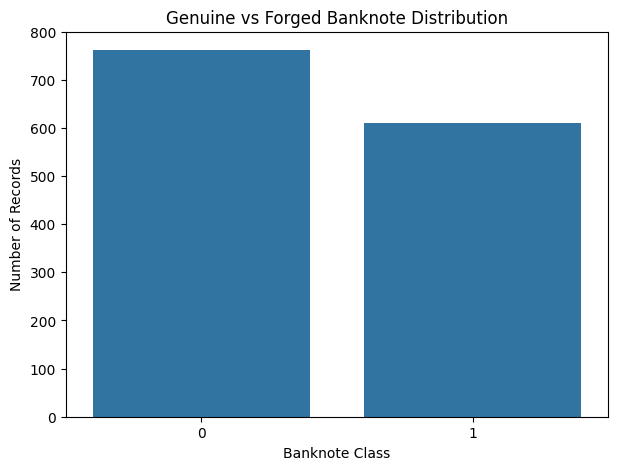

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Class')

plt.title('Genuine vs Forged Banknote Distribution')

plt.xlabel('Banknote Class')

plt.ylabel('Number of Records')

plt.show()

## Feature distribution

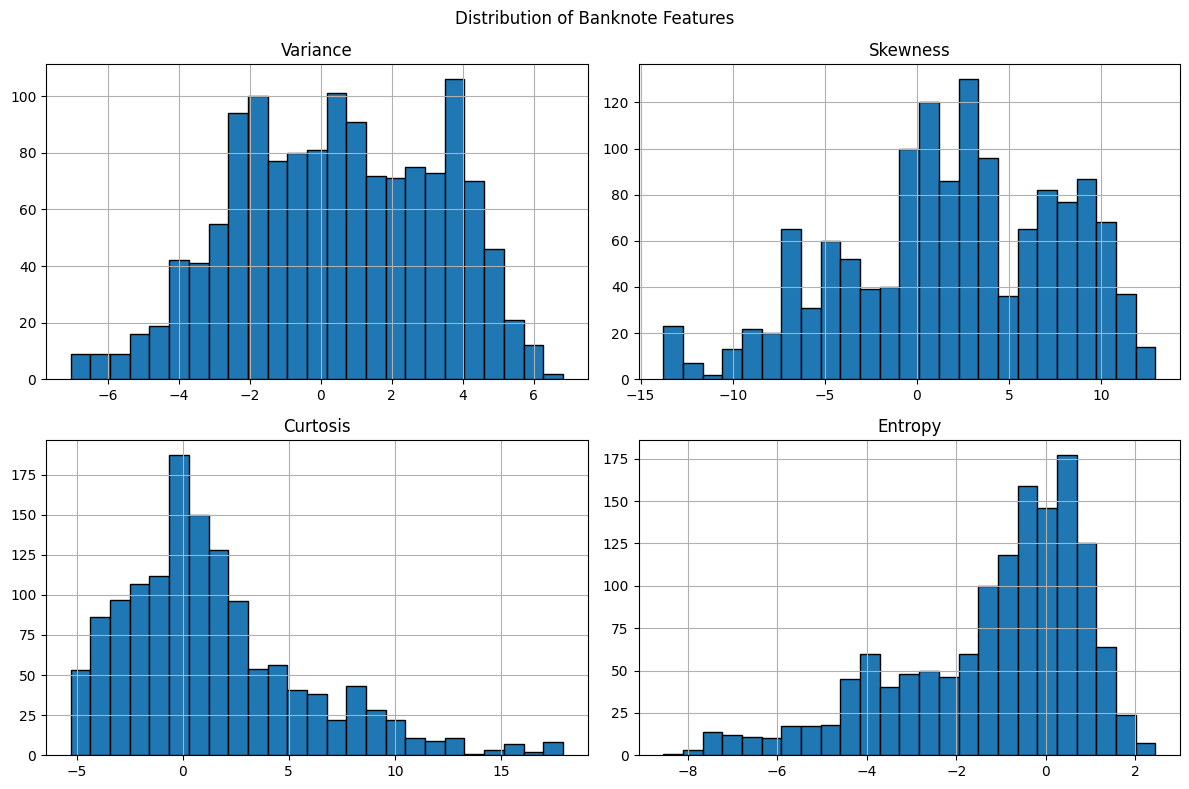

In [14]:
# Plot distributions of all input features

df[['Variance', 'Skewness', 'Curtosis', 'Entropy']].hist(
    figsize=(12, 8),
    bins=25,
    edgecolor='black'
)

plt.suptitle('Distribution of Banknote Features')

plt.tight_layout()

plt.show()

## Correlation heatmap

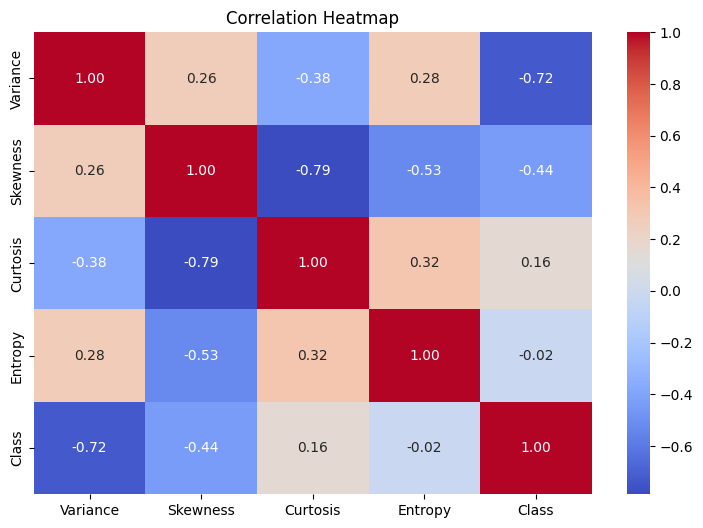

In [15]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

## Separate input features and target

- X contains the four input features.



- y contains the target class.

In [17]:
# Separate independent and dependent variables

X = df.drop('Class', axis=1)

y = df['Class']

print("Input Features (X):")

display(X.head())

Input Features (X):


,Variance,Skewness,Curtosis,Entropy
0,3.62160,8.6661,-2.8073,-0.44699
1,4.54590,8.1674,-2.4586,-1.46210
2,3.86600,-2.6383,1.9242,0.10645
3,3.45660,9.5228,-4.0112,-3.59440
4,0.32924,-4.4552,4.5718,-0.98880


In [18]:
print("Target Variable (y):")

display(y.head())

Target Variable (y):


0    0
1    0
2    0
3    0
4    0
Name: Class, dtype: int64

## Split training and testing data

We use 80% of the data for training and 20% for testing.

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (1097, 4)
Testing Data: (275, 4)


## Feature scaling using StandardScaler

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data and transform

X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

Feature scaling completed!


## Implement KNN classification

We start with K = 5 and Minkowski distance.

In [21]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model

knn = KNeighborsClassifier(
    n_neighbors=5,
    metric='minkowski'
)

# Train model

knn.fit(X_train_scaled, y_train)

print("KNN Model Training Completed!")

KNN Model Training Completed!


## Make predictions

In [22]:
# Predict test data

y_pred = knn.predict(X_test_scaled)

print("Predictions completed!")

Predictions completed!


## Compare actual and predicted values

In [23]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

display(comparison.head(20))

,Actual,Predicted
0,0,0
1,1,1
2,0,0
3,1,1
4,1,1
5,1,1
6,0,0
7,0,0
8,0,0
9,1,1


## Calculate accuracy

In [24]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("KNN Model Accuracy:", round(accuracy * 100, 2), "%")

KNN Model Accuracy: 100.0 %


## Compare four distance metrics

In [25]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

metrics = [
    'minkowski',
    'manhattan',
    'hamming',
    'chebyshev'
]

results = []

for metric in metrics:

    model = KNeighborsClassifier(
        n_neighbors=5,
        metric=metric
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        'Distance Metric': metric,
        'Accuracy': round(accuracy * 100, 2)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Distance Metric,Accuracy
0,minkowski,100.00
1,manhattan,100.00
2,hamming,48.36
3,chebyshev,100.00


Note: Hamming distance is included because your assignment requires it, but it is not naturally suited to continuous-valued features. Interpret its result cautiously.

## Visualize metric comparison

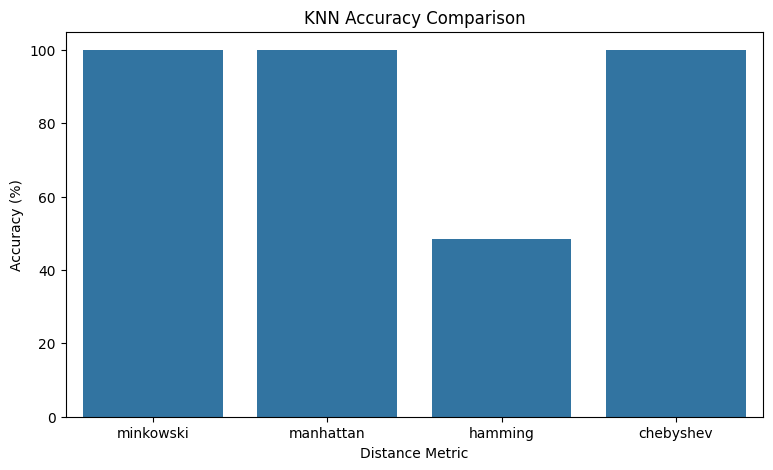

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Distance Metric',
    y='Accuracy'
)

plt.title('KNN Accuracy Comparison')

plt.xlabel('Distance Metric')

plt.ylabel('Accuracy (%)')

plt.ylim(0, 105)

plt.show()

## Test with new unseen data

In [27]:
# Create a new unseen data point

new_data = pd.DataFrame([{
    'Variance': X['Variance'].median(),
    'Skewness': X['Skewness'].median(),
    'Curtosis': X['Curtosis'].median(),
    'Entropy': X['Entropy'].median()
}])

# Scale new data using existing scaler

new_data_scaled = scaler.transform(new_data)

# Predict class

new_prediction = knn.predict(new_data_scaled)

print("Predicted Class:", new_prediction[0])

if new_prediction[0] == 0:
    print("Prediction: Genuine Banknote")
else:
    print("Prediction: Forged Banknote")

Predicted Class: 0
Prediction: Genuine Banknote


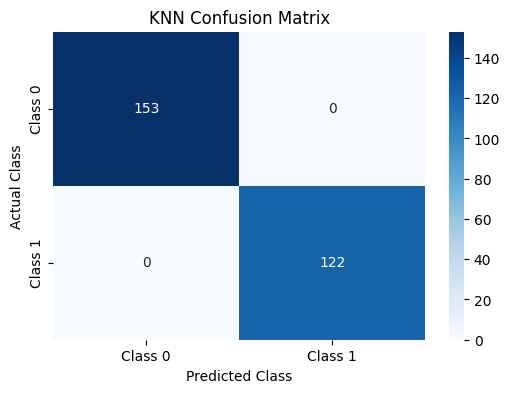

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       153
           1       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



In [28]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Class 0', 'Class 1'],
    yticklabels=['Class 0', 'Class 1']
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('KNN Confusion Matrix')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

## Conclusion

In this project, I implemented a K-Nearest Neighbors (KNN) classification model using the Banknote Authentication dataset.

The dataset contains 1,372 records, four numerical input features (Variance, Skewness, Curtosis, and Entropy), and a binary target variable (Class 0 and Class 1).

I performed data exploration, preprocessing, feature-target separation, train-test splitting, feature scaling, model training, and prediction.

I also compared four distance metrics: Minkowski, Manhattan, Hamming, and Chebyshev. Minkowski, Manhattan, and Chebyshev achieved 100% accuracy, while Hamming achieved 48.36%.

The initial KNN model achieved 100% accuracy on the test set, with precision, recall, and F1-score of 1.00 for both classes.

This project helped me understand how the KNN algorithm works, how distance metrics influence classification, and how to evaluate a machine learning model.